# MOD10 · Class 2 — Data Exploration & Preprocessing
### Student notebook

Today we turn raw data into something a model can learn from: **explore → fix missing → encode → scale → split**.

Run each cell with **Shift + Enter**. **🧪 Your turn** cells are for you to complete.
Open from **Anaconda Navigator → Jupyter Notebook**.

## 0 · Setup check

In [ ]:
import sys
%matplotlib inline
import pandas as pd, numpy as np, matplotlib
print("Python", sys.version.split()[0], "| pandas", pd.__version__)
print("Ready ✅")

Python 3.13.16 | pandas 2.2.3
Ready ✅


## 1 · Explore the data (EDA)
Before changing anything, get to know the dataset: its size, what's typical, and what's missing.

In [ ]:
import pandas as pd, numpy as np


In [ ]:
df = pd.read_csv("customers.csv")
df.head()

,customer_id,age,income,city,smoker,churn
0,1,34.0,52000.0,Montreal,no,0
1,2,NaN,61000.0,Laval,yes,1
2,3,45.0,58000.0,Montreal,no,0
3,4,29.0,NaN,Quebec,no,0
4,5,52.0,72000.0,Laval,yes,1


In [ ]:
print("shape:", df.shape)
print()
df.describe()

shape: (12, 6)



,customer_id,age,income,churn
count,12.000000,10.000000,10.000000,12.000000
mean,6.500000,40.600000,60300.000000,0.416667
std,3.605551,10.844353,10832.564075,0.514929
min,1.000000,27.000000,45000.000000,0.000000
25%,3.750000,31.750000,52750.000000,0.000000
50%,6.500000,39.500000,59500.000000,0.000000
75%,9.250000,48.000000,66750.000000,1.000000
max,12.000000,60.000000,80000.000000,1.000000


In [ ]:
#categories
# relationships between numbers

<function matplotlib.pyplot.show(close=None, block=None)>

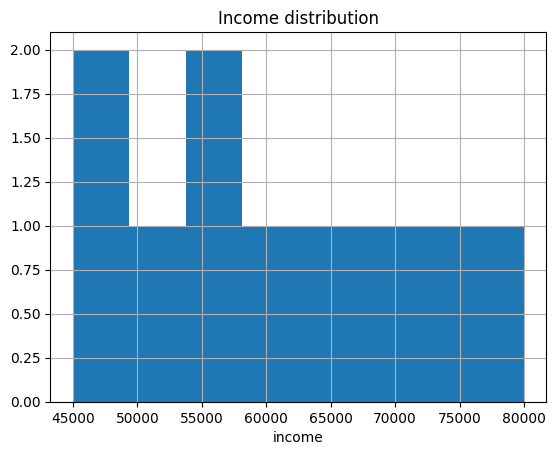

In [ ]:
#plot
import matplotlib.pyplot as plt
df['income'].hist(bins=8)
plt.title('Income distribution');plt.xlabel('income');plt.show

### 🧪 Your turn — explore
1. Print the **data types** of each column (`df.dtypes`).
2. How many customers are in each **city**? (`value_counts`)
3. Plot a **histogram** of `age`.

customer_id      int64
age            float64
income         float64
city            object
smoker          object
churn            int64
dtype: object

city
Montreal    5
Laval       4
Quebec      3
Name: count, dtype: int64



<function matplotlib.pyplot.show(close=None, block=None)>

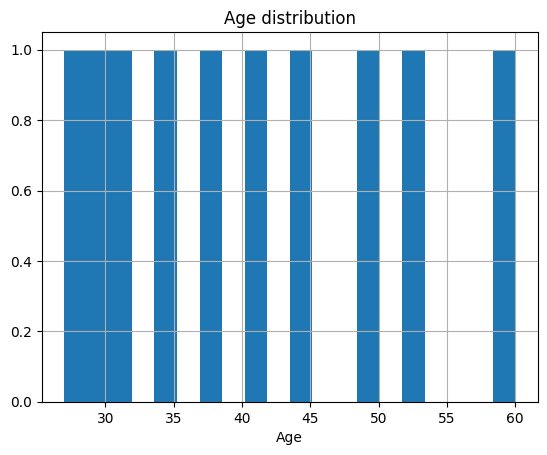

In [ ]:
# TODO 1
print(df.dtypes)
print()

# TODO 2
print(df.value_counts(df.city))
print()

# TODO 3
df['age'].hist(bins=20)
plt.title('Age distribution');plt.xlabel('Age');plt.show

## 2 · Handle missing values
Measure the gaps first, then decide: **fill** (median for numbers, mode for categories) or **drop**.

In [ ]:
# how many missing per column

### 🧪 Your turn — handle missing values
1. Fill missing **age** with the **median** age.
2. Fill missing **income** with the **median** income.
3. Confirm there are **no missing values left** (`isna().sum()`).

In [ ]:
# TODO 1
df['age']= df['age'].fillna(df['age'].median())

# TODO 2
df['income']= df['income'].fillna(df['income'].median())

# TODO 3
df.isna().sum()


,0
customer_id,0
age,0
income,0
city,0
smoker,0
churn,0


## 3 · Encode categorical variables
Models need numbers. Use **map** for binary/ordered columns and **one-hot** for unordered categories.

In [ ]:
# a boolean mask selects rows -> here, Montreal customers


### 🧪 Your turn — encode categories
1. Map **smoker** (`no`/`yes`) to `0`/`1`.
2. One-hot encode **city** with `pd.get_dummies(..., drop_first=True)`.
3. Show `df.dtypes` — are all columns numeric now?

In [ ]:
# TODO 1


# TODO 2


# TODO 3


## 4 · Scale features
Put columns on a comparable range so big-number columns don't dominate.

### 🧪 Your turn — scale
Standardize `age` and `income` with `StandardScaler` so each has mean ≈ 0.
Then print their means to check.

In [ ]:
from sklearn.preprocessing import StandardScaler

# TODO


## 5 · Train / test split
Hold out part of the data to judge the model honestly. Separate features `X` from target `y`, then split.

### 🧪 Your turn — train/test split
1. Set `X = df.drop(columns=['customer_id','churn'])` and `y = df['churn']`.
2. Split 80/20 with `random_state=42` and `stratify=y`.
3. Print the shapes of `X_train` and `X_test`.

In [ ]:
from sklearn.model_selection import train_test_split

# TODO 1


# TODO 2


# TODO 3


## 6 · Your project — Deliverable 2
You just ran the full preprocessing pipeline on a sample. Now do it on **your group's dataset**:

1. **Explore** — `head`, `shape`, `info`, `describe`, a histogram, and note 2–3 observations.
2. **Missing values** — fill or drop, and say why.
3. **Encode** — make every feature numeric.
4. **Scale** the numeric features.
5. **Split** into train/test (fit any scaler on train only).

Submit this as your Deliverable 2 notebook.

In [ ]:
# Load YOUR dataset and apply the five steps:
#
# my_df = pd.read_csv("my_dataset.csv")
# my_df.info(); my_df.isna().sum()
# ... fill/drop, encode, scale, split ...

## 7 · Bonus — what if your dataset is too clean?

Some datasets arrive already tidy — no missing values, no messy categories — which leaves nothing to practice on. You can create a **messy practice copy**, and this is a perfect job for an AI assistant. The trick: ask the AI to write the **code** that adds the noise, not to invent the data. Then *you* verify it with the checks you learned today.

**Step 1 — Ask the AI for the code (not the data).** For example:

> *“I have a clean pandas DataFrame called `df`. Write a function `add_noise(df)` that returns a messy copy (never modifies the original) with: ~5% missing values in two numeric columns, 5 exact duplicate rows, one new categorical column with inconsistent capitalization and spacing, a few extreme outliers, and one numeric column stored as text with a stray `'unknown'`. Use a fixed random seed. Add a short comment on each line.”*

**Step 2 — Read every line.** Can you explain what each one does? If not, ask the AI to clarify, or rewrite it yourself. *You must understand code before you run it* (course policy).

**Step 3 — Run it, then VERIFY.** Run today's checks on the messy copy — `.shape`, `.isna().sum()`, `.duplicated().sum()`, `.describe()`, and `value_counts()` on the new text column. Did the AI really add everything it promised? Did it introduce a bug? **Don't assume — check.**

**Step 4 — Disclose.** Note which AI tool you used and the prompt you gave it.

> 💡 **Why code, not data?** If you ask an AI to *generate the dataset itself*, it will invent plausible-looking but unreliable numbers (it “hallucinates”). Asking it for **code** keeps the data real and the process reproducible.

In [ ]:
# Paste the add_noise(df) function your AI assistant produced, then run it.
# Start from a CLEAN DataFrame (e.g. reload your original dataset).
#
# messy = add_noise(clean_df)
#
# Then VERIFY what it added:
# print(messy.shape)
# print(messy.isna().sum())
# print(messy.duplicated().sum())
# messy.describe()


---
**Next week — Supervised Learning I: Classification with KNN.** Bring your cleaned train/test split.